# Chapter 31: Case Study — The Open LUCC Workflow

*Part VI — Data, Reproducibility & Verification*

The case of this chapter is the [open-lucc-workflow](https://github.com/LambdaGeo/open-lucc-workflow) repository (release v1.1.0, DOI 10.5281/zenodo.23415814), by Costa, Bezerra and Alves.

<div class="admonition note">
<p class="admonition-title">What runs here</p>
<p>The runnable cells clone the workflow at its release tag, install its pinned packages in a separate environment, and run the two cheapest levels of repetition: a check of the archived record (seconds) and the whole chain on a synthetic input (about 20 seconds). They need network access to GitHub and PyPI. The run over Brazil takes from 40 minutes to 6.5 hours and is shown as commands, with the measured results.</p>
</div>

## Learning Objectives

By the end of this chapter you will be able to:

- Describe the five stages of a traceable land-use change experiment, and the artifact each one leaves
- Read a declared source, a grid specification and a declared model as files rather than as code
- Repeat the experiment at the level of effort you can afford, from a check of the archived record to the full run
- Read acceptance criteria for what they show and what they leave open
- Fork the workflow and replace its sources or its model while keeping the checks

In [1]:
# Standard imports
import json
import subprocess
import tomllib
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

Chapters 28 to 30 built the pieces one at a time: a grid filled from declared sources, a run that leaves a record, and a check against TerraME and LuccME. This chapter runs them together, over the whole of Brazil. The model is declared, not calibrated, and its maps are **not a land-use projection**: what the case demonstrates is that the whole process, from public files to allocated maps, can be repeated and checked by someone else.

![The Open LUCC workflow: five stages, a run over Brazil, and three claims](../../assets/images/open_lucc_workflow.png)

*The five stages of the Open LUCC workflow, the run over Brazil on the 10.56 and 5.28 km grids, and the three points of the case. From open-lucc-workflow, `docs/graphical_abstract.png` (CC BY 4.0).*

## Five Stages, Five Artifacts

| Stage | What it declares | What it writes | Read by |
|---|---|---|---|
| 1. Sources | each input with origin URL, licence, access and SHA-256 (`pipeline/grid/sources.toml`) | the downloaded files, checked by hash | stage 2 |
| 2. Input raster | the derived variables of each cell, as DisSCube derivations | a multiband GeoTIFF with its provenance record | E2 of Chapter 30; structural checks |
| 3. Model | the model and the scenario, in TOML files | the allocated maps | E3 of Chapter 30 |
| 4. Record | — | an experiment record: input and output hashes, versions, environment | a script that verifies it from a clean clone |
| 5. Acceptance | criteria written before the runs (`acceptance.toml`) | pass or fail, criterion by criterion | the reader |

Stages 2 and 3 take over the work that TerraME's `fill` and LuccME did in the original workflow. Stages 1, 4 and 5 have no counterpart there: they are what makes the experiment repeatable by someone else.

## The Model Grid

The grid is a DisSCube `GridSpec` in the Brazil Data Cube Albers projection (EPSG:10857). The Brazil Data Cube divides the country into tiles of 105.6 km; the workflow uses two cell sizes that divide a tile exactly, so that cells never straddle a tile border:

| Grid | Cells per tile side | Grid size | Cells inside Brazil | Area of a cell |
|---|---|---|---|---|
| 10.56 km | 10 | 450 × 520 | 77,238 | 111.5 km² |
| 5.28 km | 20 | 900 × 1,040 | 307,419 | 27.9 km² |

The Brazil Data Cube enters only as this *specification*: the inputs of the model are not Brazil Data Cube products. The 10.56 km grid is the nearest division of the tile to the 10 km cells of the national LuccME-BR scenarios; the 5.28 km grid halves it, to show that the chain scales to four times as many cells.

## Stage 1: Declared Sources

Every input is a block of `sources.toml` with where it comes from and what its bytes must hash to. The land cover is a file you have already met — the LuccME-BR land-cover NetCDF of Chapters 9 and 16 — read here one variable at a time:

```toml
[[source]]
id = "lc_forest_vegetation"
type = "file"
path = "netcdfs/LUCCMEBR_land_cover_type_100km2_2000.nc"
variable = "veg"
url = "https://zenodo.org/records/5123560/files/LUCCMEBR_land_cover_type_100km2_2000.nc?download=1"
sha256 = "dc679ea733e9ee14378b7fc872a9199b219e998418c2ea8bb1d1d73676df332a"
```

The other inputs are national layers of federal agencies: conservation units (MMA), indigenous lands (FUNAI), rural settlements (INCRA), municipal seats, railways and state roads (ANA, from IBGE and DNIT), federal roads and the country boundary (IBGE), and the road and port networks of TerraME's GPM package for the network cost. "Open" turned out to need a column of its own for each source: CNUC is CC BY; FUNAI and INCRA state no open reuse licence, so their files are served from an unmodified provisional copy, to be withdrawn on request; IBGE and ANA state no licence, so their files are downloaded directly and never redistributed. When a file cannot be redistributed, the hash still lets a reader check that the file they obtained is the one that was used.

## Stage 2: The Input Raster

A DisSCube pipeline file — Chapter 28's format — derives 16 bands on each grid: the shares of seven land-use classes, the drivers (distances to roads, railways and municipal seats, the network cost to ports, the protected share of each cell, rural settlements) and a mask. The network cost is DisSCube's `network_cost`, the operator Chapter 30 left as an open case against TerraME; the workflow uses it, and states that the effect of that difference on the allocation was not measured. Building the raster takes about 1.5 minutes at 10.56 km and 3 minutes at 5.28 km.

## Stage 3: The Verification Model

The model has the structure of LuccME-BR — a demand, a potential with a spatial-lag term, and a continuous allocation with saturation (Chapter 26) — but not its parameters. Replicating LuccME-BR was never the aim; the model only has to exercise the chain. The parameters come from one short file of weights, `model/parameter_weights.toml`, the only place where numbers are chosen by hand:

```toml
[rho]
value = 0.90                 # spatial-lag weight, one value for every class

[weights.forest_vegetation]  # stays forest far from roads and ports and inside protected areas
e_connport = 0.02
e_uroads   = 0.02
c_ucspas   = 0.03

[weights.pasture_management] # expands near roads and ports, outside protected areas
e_uroads   = -0.02
e_connport = -0.015
c_ucspas   = -0.03
```

A script turns each weight *w* into a coefficient β = *w* / σ, where σ is the standard deviation of the driver in the 10.56 km raster, so that drivers in different units contribute comparably, and computes each constant so that the mean potential of a class is zero at the start. The result and the hashes of its inputs are recorded. The scenario (`model/scenario.toml`) runs 15 years in which forest loses 0.20% of its area a year, shared among pasture (50%), agriculture (30%), mosaic (10%) and forestry (10%). Nothing here was fitted to observed change, which is why the maps must not be read as projections.

## Stages 4 and 5: The Record and the Criteria

Each run writes an experiment record — the DisSModel `ExperimentRecord` of Chapter 29, with the SHA-256 of the input and output rasters, the package versions and the environment — and a `metrics.json` with the iterations and the largest error of every year. The reported run is archived in the repository under `reported/v1.1.0/`, with its logs, its `requirements.lock` and a description of the machine.

The criteria were written in `acceptance.toml` and frozen at a named commit on 9 October 2026, before the reported runs (Chapter 29 showed the file): the allocation meets the demand within 1,000 km² in every year, a repeated run is identical, and the class areas of the two grids agree within 0.5% of the mapped area.

## Four Levels of Repetition

The workflow can be repeated at four depths, each a `make` target:

| Level | Command | What it does | Time |
|---|---|---|---|
| 0 | `make check-reported` | checks the archived record of the reported run against the criteria | seconds |
| 1 | `make small` | runs the whole chain on a synthetic input raster, no downloads | about 15–20 s |
| 2 | `make reproduce-10k` | rebuilds the 10.56 km run from the declared sources and compares it with the record | 40–90 min |
| 3 | `make full` | both grids, the repeat run, and the acceptance criteria — the authors' run | about 6.5 h |

The cells below run levels 0 and 1. The first clones the release and builds its environment — a separate virtual environment, with the exact versions the release pins:

In [2]:
WORK = Path("evidence")
WORK.mkdir(exist_ok=True)
olw = WORK / "open-lucc-workflow"
if not olw.exists():
    subprocess.run(["git", "-c", "advice.detachedHead=false", "clone", "-q", "--depth", "1",
                    "--branch", "v1.1.0", "https://github.com/LambdaGeo/open-lucc-workflow.git", str(olw)], check=True)

def make(target):
    run = subprocess.run(["make", target], cwd=olw, capture_output=True, text=True)
    return run.returncode, run.stdout

code_env, _ = make("env")                      # python -m venv .venv && pip install -r requirements-dev.txt
print("environment ready" if code_env == 0 else "make env failed")

environment ready


**Level 0** reads the archived metrics of the reported run and applies the frozen criteria to them — no model runs:

In [3]:
code_0, out = make("check-reported")
print(out)

.venv/bin/python scripts/check_reported.py --reported reported/v1.1.0
PASS  demand_met (5.28 km)     {'max_error_km2': 999.7489366000518, 'worst_final_class_error_km2': 989.8940607062541, 'tolerance_km2': 1000.0, 'max_iterations': 1276}
PASS  demand_met (10.56 km)    {'max_error_km2': 999.7602201374248, 'worst_final_class_error_km2': 974.1296922629699, 'tolerance_km2': 1000.0, 'max_iterations': 1193}
PASS  repeat_identical         {'same_input': True, 'same_output': True}
PASS  area_vs_coarser          {'max_class_area_diff_fraction': 0.00209182464554088, 'tolerance': 0.005}



**Level 1** runs the whole chain on a synthetic input raster of 60 × 60 cells: the model twice on the fine grid (to check that a repeat is identical), once on a coarser grid, the criteria, the verification of every record, and a summary table:

In [4]:
code_1, out = make("small")
lines = out.splitlines()
print("\n".join(l for l in lines if l.startswith(("PASS", "FAIL", "record", "|"))))

PASS  demand_met         {'max_error_km2': 428.8090563009173, 'worst_final_class_error_km2': 428.809056042297, 'tolerance_km2': 1000.0, 'max_iterations': 0}
PASS  repeat_identical   {'max_abs_diff': 0.0, 'bytes_identical': True, 'tolerance': 0.0}
PASS  area_vs_coarser    {'max_class_area_diff_fraction': 2.2810220886967842e-05, 'tolerance': 0.005}
record verified
record verified
record verified
| Grid | Cells | Demand met | Iterations per year | Repeat run identical | Area per class vs coarser grid | Time | Peak memory |
|---|---:|---|---|---|---|---:|---:|
| synthetic_coarse | 900 | n/a | 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 | n/a | n/a | 3.0 s | 305 MB |
| synthetic_fine | 3,600 | yes (max 428.81 km²) | 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 | yes, bytes | 0.0000 of area | 3.5 s | 308 MB |


All three criteria pass — and the iteration counts in the table are all zero. On the synthetic input, the allocation accepts its first pass in every year, because the error never reaches the 1,000 km² tolerance: it grows from 30 km² in the first year to 429 km² in the last. This is the limit of the demand criterion that Chapter 29 demonstrated on a toy run, met here on a real one: the criterion shows that the iteration converged within its limit, not that the model moved. The synthetic case exists to check that the chain runs end to end in seconds — it runs in continuous integration on every push — not to exercise the allocation. The run over Brazil does that.

## The Run over Brazil

Levels 2 and 3 need the declared sources, so they need the network and time:

```bash
git clone https://github.com/LambdaGeo/open-lucc-workflow.git && cd open-lucc-workflow
make env
make reproduce-10k      # level 2: the 10.56 km run, compared with the record (40–90 min)
make full               # level 3: both grids and the repeat run (about 6.5 h)
```

The archived record is enough to see what the reported run did. The cell below reads the metrics of both grids from the release and draws the iterations and the largest error of each year:

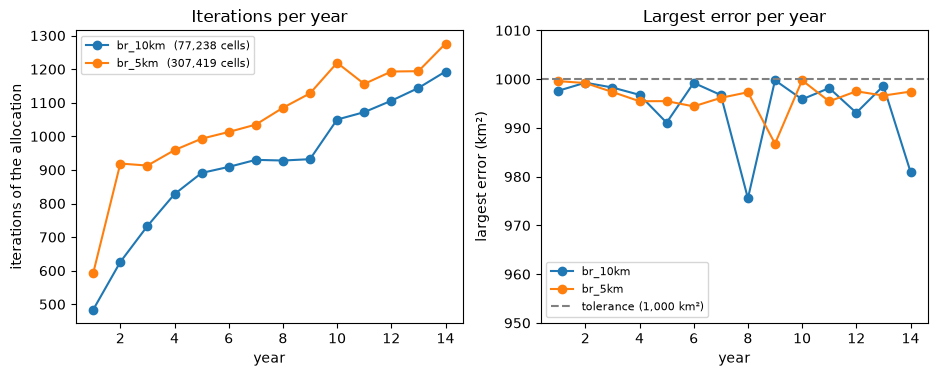

br_10km:    36 min, peak 0.38 GB, output f060cc08686e…, versions {'disscube': '0.6.0', 'disslucc': '0.5.0', 'dissmodel': '0.6.6'}
br_5km:   173 min, peak 0.79 GB, output 895a11e8e3a4…, versions {'disscube': '0.6.0', 'disslucc': '0.5.0', 'dissmodel': '0.6.6'}


In [5]:
reported = olw / "reported" / "v1.1.0"
runs = {label: json.loads((reported / f"metrics_{label}.json").read_text()) for label in ["br_10km", "br_5km"]}

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for label, m in runs.items():
    years = range(1, len(m["iterations_per_step"]))          # year 0 is the initial state: no allocation
    axes[0].plot(years, m["iterations_per_step"][1:], marker="o", label=f"{label}  ({m['cells_in_mask']:,} cells)")
    axes[1].plot(years, m["max_error_per_step"][1:], marker="o", label=label)
axes[0].set(xlabel="year", ylabel="iterations of the allocation", title="Iterations per year")
axes[1].axhline(1000, color="grey", linestyle="--", label="tolerance (1,000 km²)")
axes[1].set(xlabel="year", ylabel="largest error (km²)", title="Largest error per year", ylim=(950, 1010))
for ax in axes:
    ax.legend(fontsize=8)
plt.show()

for label, m in runs.items():
    print(f"{label}: {m['run_seconds'] / 60:5.0f} min, peak {m['peak_rss_mb'] / 1000:.2f} GB, "
          f"output {m['output_sha256'][:12]}…, versions {m['versions']}")

Over Brazil the allocation works: 484 to 1,276 iterations a year, the largest error just under the tolerance every year — by construction, since the iteration stops as soon as it is below it. Forest loses 2.77% of its area, as the scenario prescribes. The 5.28 km run was repeated on the same machine and gave an output identical byte for byte, and the class areas of the two grids differ by at most 0.21% (criterion 0.5%). All three criteria are met on both grids.

The criteria show that the chain runs and is consistent. They say nothing about whether the model is right, and each has its own blind spot: the demand criterion cannot see a class whose yearly change is below the tolerance (forestry gains about 740 km² a year); the repeat shows determinism on one machine; and the comparison of the two grids mixes the effect of resolution with that of their different masks — the 10.56 km grid maps 0.5% more area because its border cells are larger. An analysis made *after* the runs, on the 76,254 cells that both masks cover entirely, shrinks the forest difference between the grids from 17,928 km² to 237 km²; it is descriptive, and it is not a criterion.

## Five Computers, One Surprise

Level 2 was repeated, from a fresh clone and an empty cache, on five computers: the authors' desktop, two authors' laptops, and the computers of two researchers who are not authors. On the four x86-64 machines — Linux and Windows with WSL2, Python from 3.12 to 3.14 — the input and output rasters had the same SHA-256 as the reported run. On the fifth, a Mac with an Apple M3 processor, `make reproduce-10k` reported **DIFFERS**: both hashes were different.

Nothing was wrong with the run. The iteration counts of the 14 years, the largest error of each year and the final area of every class were equal. Every value of the output raster was equal; its compressed bytes differed in every strip, because each platform's GDAL encodes DEFLATE differently. In the input raster, one value out of 1,549,332 differed, by 1.8×10⁻¹² — a rounding of a 32-bit float that fell on the other side. This is the case Chapter 29 used to separate a file hash from a hash of the values: a check that compared files would call a correct run a failure. The repository now ships a script that compares two rasters by their values, for exactly this situation.

## Fork and Adapt

The repository is meant to be forked, and the model of the demonstration is meant to be replaced. A group with its own study area or its own calibrated model changes one thing at a time, and repeats the check after each change:

1. **Start from the baseline.** `make check-reported` and `make small` must pass on your machine before anything changes.
2. **Replace the sources.** Edit `pipeline/grid/sources.toml` (URL and SHA-256 of each layer) and the derivations that say which operator builds each band; `make grids` rebuilds the input raster with its record.
3. **Replace the model.** Edit `model/parameter_weights.toml` and `model/scenario.toml` — or bring coefficients calibrated on your own data — and regenerate the model file with `scripts/make_parameters.py`. Another DisSLUCC component is a class that follows its protocols, built in an executor.
4. **Write your criteria first.** Put them in `acceptance.toml` and commit them before the run you will report.
5. **Run and share.** `make full`, then publish the fork with its record, so that others can repeat your run the way you repeated this one.

The checks of Chapter 30 do not need to be repeated for this: they establish that the components behave like TerraME and LuccME, at the pinned versions. And if your model needs a component that DisSLUCC does not have, the original software remains the right tool.

## Exercises

1. **Read the record.** Open `reported/v1.1.0/metrics_br_5km.json` and `metrics_br_5km_repeat.json` of the cloned repository. Which fields must be equal for the repeat criterion to pass, and which are allowed to differ?
2. **Make the synthetic case move.** The synthetic case allocates with zero iterations. Find in the repository which parameter of the scenario or of the model you would change so that the allocation has to iterate on the synthetic input, change it in your copy, and run `make small` again. Do the criteria still pass?
3. **Change one weight.** In your copy, double the weight of `c_ucspas` for pasture in `model/parameter_weights.toml` and regenerate the model file. Predict, before running anything, which acceptance criterion could fail and why.
4. **Licences.** Pick two sources of `pipeline/grid/sources.toml` and find the licence their providers state. May the files be redistributed? What does the workflow do when they may not?
5. **Your own levels.** For a project of your own, write the table of its four levels of repetition: what each level runs, what it compares with, and how long it takes.

In [6]:
# Your code here

## Summary

### Key concepts introduced

- A land-use change experiment as five stages — sources, input raster, model, record, acceptance — each with a declared input and an artifact that a check reads
- The Brazil Data Cube grid as a specification only, and two cell sizes that divide its tiles exactly
- Declared sources with origin, licence, access and SHA-256, and what to do when a file may not be redistributed
- A verification model whose parameters come from one short file of weights and a script, with the structure of LuccME-BR and none of its calibration
- Four levels of repetition, from a check of the archived record in seconds to the full run in hours
- Acceptance criteria met over Brazil, and what each of them cannot see — including a synthetic case that passes without moving
- Identical hashes on four x86-64 computers and equal values, not equal bytes, on an ARM Mac
- Fork and adapt: replace the sources and the model, write the criteria first, keep the checks

Part VII starts from a model that can be trusted to run correctly and asks how far its answer depends on uncertain parameters — ensembles and sensitivity analysis, in Chapter 32.

## Further Reading

- Costa, S. S., Bezerra, D. S., & Alves, J. M. P. (2026). *Open LUCC workflow* (Version 1.1.0) [Computer software]. Zenodo. <https://doi.org/10.5281/zenodo.23415814>
- Bezerra, F. G. S. et al. (2022). New land-use change scenarios for Brazil: Refining global SSPs with a regional spatially-explicit allocation model. *PLOS ONE*, 17(4), e0256052. <https://doi.org/10.1371/journal.pone.0256052> — LuccME-BR
- Bezerra, F. G. S. et al. (2021). *LuccME/INLAND land-use scenarios for Brazil 2050* [Data set]. Zenodo. <https://doi.org/10.5281/zenodo.5123560> — the land-cover layer of stage 1, and of Chapters 9 and 16
- Ferreira, K. R. et al. (2020). Earth observation data cubes for Brazil: Requirements, methodology and products. *Remote Sensing*, 12(24), 4033. <https://doi.org/10.3390/rs12244033>
- Ren, Y. et al. (2019). Spatially explicit simulation of land use/land cover changes: Current coverage and future prospects. *Earth-Science Reviews*, 190, 398–415. <https://doi.org/10.1016/j.earscirev.2019.01.001>
- Murray-Rust, P. (2008). Open data in science. *Serials Review*, 34(1), 52–64. <https://doi.org/10.1016/j.serrev.2008.01.001>
- National Academies of Sciences, Engineering, and Medicine (2019). *Reproducibility and Replicability in Science*. <https://doi.org/10.17226/25303>